# 文件的输入输出

Polars 的文件读写很快，CSV、Excel、JSON、Parquet、IPC 这些格式都能处理。读写本身不难，难的是「格式不干净时怎么把参数调对」：表头有没有、类型推断靠不靠谱、多余空白算不算内容。

这一章按格式分节，每节都从实际会遇到的脏数据出发，逐个确认有代表性的选项。

In [1]:
import polars as pl
from helper.jupyter import row, capture_except

## CSV 文件

CSV 的格式比较松散，读之前往往要先定几件事：有没有表头、表头占几行、类型怎么推断、多余的空白怎么处理。

这些选项一旦设错，要么报错，要么更糟——读进来一列全变成字符串，后面所有计算都跟着错。下面用实际数据逐个确认。

### 读取

#### 表头

CSV 有时带表头，有时不带，表头也可能跨两行。下面用这份数据确认表头的处理方式。

In [2]:
%%writefile data/csv_header.csv
A,B
a,b
0,1
2,3
4,5

Overwriting data/csv_header.csv


- `df1` — 默认把第 1 行当作表头读入。
- `df2` — 设 `has_header=False` 后第 1 行也变成数据，列名用 `new_columns` 指定。
- `df3` — 用 `skip_rows` 跳过开头的 N 行。
- `df4` — 用 `skip_rows_after_header` 跳过表头之后的 N 行。
- `df5` — 先不带表头读开头 2 行，按列拼接出列名。表头跨两行时这样合并。

In [3]:
fn = 'data/csv_header.csv'
df1 = pl.read_csv(fn)
df2 = pl.read_csv(fn, has_header=False, new_columns=['x', 'y'])
df3 = pl.read_csv(fn, skip_rows=1)
df4 = pl.read_csv(fn, skip_rows_after_header=1)

df_header = pl.read_csv(fn, n_rows=2, has_header=False)
columns = df_header.select(pl.all().str.join('-')).row(0)
df5 = pl.read_csv(fn, has_header=False, skip_rows=2, new_columns=columns)
row(df1, df2, df3, df4, df5)

A,B
str,str
"""a""","""b"""
"""0""","""1"""
"""2""","""3"""
"""4""","""5"""
x,y
str,str
"""A""","""B"""
"""a""","""b"""
"""0""","""1"""


`infer_schema=True`（默认）时，Polars 只看开头 `infer_schema_length` 行来决定各列的类型：先猜类型，再按这个类型去解析剩下的行。

猜错了就会出错——这个范围之外若出现别的类型的值，解析会直接失败。下面用这份数据确认。

In [4]:
%%writefile data/csv_different_type.csv
A,B
0,1
2,3
4,5
a,5.5
10,20

Overwriting data/csv_different_type.csv


`infer_schema_length` 的默认值是 100，对大多数文件够用。下面的代码只取 2 行来推断，于是第 4 行的 `a` 会引发错误——这正好演示了「推断范围不够」的后果。

In [5]:
%%capture_except
df = pl.read_csv('data/csv_different_type.csv', infer_schema_length=2)

ComputeError: could not parse `a` as dtype `i64` at column 'A' (column number 1)

The current offset in the file is 15 bytes.

You might want to try:
- increasing `infer_schema_length` (e.g. `infer_schema_length=10000`),
- increasing `infer_schema_files` (e.g. `infer_schema_files=50`),
- specifying correct dtype with the `schema_overrides` argument
- setting `ignore_errors` to `True`,
- adding `a` to the `null_values` list.

Original error: ```invalid primitive value found during CSV parsing```


错误信息里会给出几种解法。下面的代码把这些解法依次试了一遍。

- **`df1`** — 加大 `infer_schema_length`，`A` 读成 `str`、`B` 读成 `f64`。
- **`df2`** — `infer_schema_length=None` 从所有行推断类型，再用 `null_values=['a']` 把 `a` 当 NULL，于是 `A` 成为 `i64`。
- **`df3`** — `ignore_errors=True`，把不符合推断类型的值变成 NULL。
- **`df4`** — 用 `schema_overrides` 明确指定类型，再用 `ignore_errors=True`，既省内存又不会因为个别脏值报错。

In [6]:
fn = 'data/csv_different_type.csv'
df1 = pl.read_csv(fn, infer_schema_length=1000)
df2 = pl.read_csv(fn, infer_schema_length=None, null_values=['a'])
df3 = pl.read_csv(fn, infer_schema_length=2, ignore_errors=True)
df4 = pl.read_csv(fn, schema_overrides={'A':pl.Int16, 'B':pl.Float32}, ignore_errors=True)
row(df1, df2, df3, df4)

A,B
str,f64
"""0""",1.0
"""2""",3.0
"""4""",5.0
"""a""",5.5
"""10""",20.0
A,B
i64,f64
0,1.0
2,3.0


列值末尾有空白时，Polars 的标准引擎会原样保留，并把该列判定为 `str`——因为 `"4 "` 确实不是合法的整数。

下面用这份数据确认，对比一下标准引擎和 PyArrow 引擎的差别。

In [7]:
%%writefile data/csv_trailing_space.csv
str,int,float
日本語 ,4 ,5.67 
abc ,5 ,1.23 

Overwriting data/csv_trailing_space.csv


这份数据在标准引擎和 `use_pyarrow=True` 下结果不同。

- `df1` — 标准引擎下所有列都是 `str`，因为末尾空白让它无法判定数值。
- `df2` — 设 `use_pyarrow=True` 后，`int` 和 `float` 两列被解释成数值，PyArrow 的解析器会自动去掉空白。

选哪个取决于数据的干净程度：格式规范就用标准引擎，格式杂乱时 PyArrow 更宽容。

In [8]:
fn = 'data/csv_trailing_space.csv'
df1 = pl.read_csv(fn)
df2 = pl.read_csv(fn, use_pyarrow=True)
row(df1, df2)

str,int,float
str,str,str
"""日本語 ""","""4 ""","""5.67 """
"""abc ""","""5 ""","""1.23 """
str,int,float
str,i64,f64
"""日本語 """,4,5.67
"""abc """,5,1.23


想把标准引擎读出的字符串转成数值，就得自己写转换：先去空白，再按整数 → 小数 → 原字符串的顺序尝试。

写成函数的好处是逻辑集中，坏处是必须逐列调用——因为每列的目标类型不同，没法用一个 return_type 概括。

In [9]:
from polars.exceptions import InvalidOperationError


def try_cast_to_number(s: pl.Series) -> pl.Series:
    """去掉空白，按 Int64 → Float64 → 原字符串的顺序尝试转换。"""
    stripped = s.str.strip_chars()
    for dtype in (pl.Int64, pl.Float64):
        try:
            return stripped.cast(dtype)
        except InvalidOperationError:
            continue
    return stripped


# 各列的类型会变，所以先按列应用，再合成一个数据框
df_converted = pl.DataFrame({name: try_cast_to_number(df1[name]) for name in df1.columns})
row(df1, df_converted)

str,int,float
str,str,str
"""日本語 ""","""4 ""","""5.67 """
"""abc ""","""5 ""","""1.23 """
str,int,float
str,i64,f64
"""日本語""",4,5.67
"""abc""",5,1.23


#### 读取多个文件

实际数据常常按天、按对象拆成很多文件。Polars 的路径支持通配符，可以把它们一次读成一张表。

下面的例子批量读取股票价格的 CSV：先把数据下载到 `data/stock`。

In [10]:
from helper.utils import download_folder_from_github, print_folder_structure
download_folder_from_github("https://github.com/jeroenjanssens/python-polars-the-definitive-guide/tree/main/data/stock", "data/stock")

data/stock exists, please delete and try again.


下载后的目录按股票代码分子目录，每个子目录里放按年份的 CSV。

In [11]:
print_folder_structure("data/stock", max_file_count=3)

|-- asml
    |-- 1999.csv
    |-- 2000.csv
    |-- 2001.csv
    |-- ...
|-- nvda
    |-- 1999.csv
    |-- 2000.csv
    |-- 2001.csv
    |-- ...
|-- tsm
    |-- 1999.csv
    |-- 2000.csv
    |-- 2001.csv
    |-- ...


要一次读入所有 CSV，在路径里用通配符 `**` 递归匹配子目录即可；Polars 会把所有文件当成一个数据源，列名和类型不一致时按上位类型统一。

In [12]:
df_stock = pl.read_csv('data/stock/**/*.csv', try_parse_dates=True)
df_stock

symbol,date,open,high,low,close,adj close,volume
str,date,f64,f64,f64,f64,f64,i64
"""ASML""",1999-01-04,11.765625,12.28125,11.765625,12.140625,7.522523,1801867
"""ASML""",1999-01-05,11.859375,14.25,11.71875,13.96875,8.655257,8241600
"""ASML""",1999-01-06,14.25,17.601563,14.203125,16.875,10.456018,16400267
"""ASML""",1999-01-07,14.742188,17.8125,14.53125,16.851563,10.441495,17722133
"""ASML""",1999-01-08,16.078125,16.289063,15.023438,15.796875,9.787995,10696000
…,…,…,…,…,…,…,…
"""TSM""",2023-06-26,102.019997,103.040001,100.089996,100.110001,99.125954,8560000
"""TSM""",2023-06-27,101.150002,102.790001,100.019997,102.080002,101.076591,9732000
"""TSM""",2023-06-28,100.5,101.879997,100.220001,100.919998,99.927986,8160900


这份数据本来就有股票名的列，不必再把文件名做成列。想知道某行来自哪个文件时，用 `include_file_paths` 指定列名即可。

Polars 2.0 的 `read_csv()` 也接受这个参数，但这里用延迟求值的 `scan_csv()`：它返回 `LazyFrame`，不立刻读数据，要看内容才调 `collect()`。

In [13]:
df_stock = pl.scan_csv('data/stock/**/*.csv', try_parse_dates=True, include_file_paths="path")
df_stock

In [14]:
df_stock.collect()

symbol,date,open,high,low,close,adj close,volume,path
str,date,f64,f64,f64,f64,f64,i64,str
"""ASML""",1999-01-04,11.765625,12.28125,11.765625,12.140625,7.522523,1801867,"""data/stock/asml/1999.csv"""
"""ASML""",1999-01-05,11.859375,14.25,11.71875,13.96875,8.655257,8241600,"""data/stock/asml/1999.csv"""
"""ASML""",1999-01-06,14.25,17.601563,14.203125,16.875,10.456018,16400267,"""data/stock/asml/1999.csv"""
"""ASML""",1999-01-07,14.742188,17.8125,14.53125,16.851563,10.441495,17722133,"""data/stock/asml/1999.csv"""
"""ASML""",1999-01-08,16.078125,16.289063,15.023438,15.796875,9.787995,10696000,"""data/stock/asml/1999.csv"""
…,…,…,…,…,…,…,…,…
"""TSM""",2023-06-26,102.019997,103.040001,100.089996,100.110001,99.125954,8560000,"""data/stock/tsm/2023.csv"""
"""TSM""",2023-06-27,101.150002,102.790001,100.019997,102.080002,101.076591,9732000,"""data/stock/tsm/2023.csv"""
"""TSM""",2023-06-28,100.5,101.879997,100.220001,100.919998,99.927986,8160900,"""data/stock/tsm/2023.csv"""


不是 CSV 的文本，只要把一行读成一列，也能用 Polars 的字符串操作解析——这比写 Python 循环快得多，因为解析本身也走 Polars 的引擎。

下面的 `variables_dump.txt` 是每行并排多个「变量 = 值」的转储。

In [15]:
%%writefile data/variables_dump.txt
A = 1, B = 2, C = 3.23
A = 11, B = 22, C = 33.23
B = 30, C = 20.0
D = 10, A = 3

Overwriting data/variables_dump.txt


读取时把 `separator` 指定为 NULL 字符 `"\x00"`：文本里不会出现这个字符，所以行不会被切分，每行整体成为一个值。

之后用下面的操作重新拼成表：

* `.str.split(",")` — 按 `,` 切分各行
* `.explode("s")` — 把切出的列表展开成行
* `.str.extract_groups(...)` — 用正则取出变量名（`name`）和值（`value`）
* `.pivot(...)` — 把变量名变成列，一行对应一个样本
* `.cast(pl.Float64)` — 把值转成浮点数

最后找出小数部分全为 0 的列，转回 `Int64`——这样整数列不会显示成 `3.0`。

In [16]:
df = pl.read_csv(
    "data/variables_dump.txt", has_header=False, separator="\x00", new_columns=["s"]
)

df_vars = (
    df.select(pl.col("s").str.split(","))
    .with_row_index()
    .explode("s")  # 一个单元格一个变量
    .with_columns(
        pl.col("s").str.extract_groups(r"(?<name>\w)+\s*=\s*(?<value>.+)")
    )
    .unnest("s")  # 分成 name / value 两列
    .pivot(on="name", index="index")
    .with_columns(pl.exclude("index").cast(pl.Float64))
)

# 小数部分恒为 0 的列转回 Int64
int_cols = (
    df_vars.select((pl.col(pl.Float64) % 1 == 0).all())
    .transpose(include_header=True)
    .filter("column_0")
    .get_column("column")
    .to_list()
)

df_vars = df_vars.with_columns(pl.col(int_cols).cast(pl.Int64))
row(df, df_vars)

shape: (4, 1) s str "A = 1, B = 2, C = 3.23" "A = 11, B = 22, C = 33.23" "B = 30, C = 20.0" "D = 10, A = 3" 
 shape: (4, 5) index A B C D u32 i64 i64 f64 i64 0 1 2 3.23 null 1 11 22 33.23 null 2 null 30 20.0 null 3 3 null null 10

### 写出

用 `DataFrame.write_csv()` 可以把数据框直接输出成 CSV 文件，参数和读取端基本对称。

In [17]:
df1.write_csv('data/csv_output_utf8.csv')

`write_csv()` 能指定 `include_header`、`separator`、`line_terminator` 等格式参数，但没有直接指定编码的选项。

要写成 Shift-JIS（比如给日本的旧系统用），可以先写进 `StringIO`，再把内容转码保存——多一步，但不影响性能。

In [18]:
import io

buf = io.StringIO()
df1.write_csv(buf)

with open('data/csv_output_shiftjis.csv', 'w', encoding='shift-jis') as f:
    f.write(buf.getvalue())

## Excel 文件

Excel 的读写用 `read_excel()` 和 `DataFrame.write_excel()`。

读取有 `calamine`、`xlsx2csv`、`openpyxl` 三个引擎，默认的 `calamine` 最快，因为它用 Rust 直接解析压缩包，不经过 Python 层。写出用 `xlsxwriter` 库。必要的库用下面的命令安装。

```
conda install fastexcel xlsxwriter
```

### 读取

用 `read_excel()` 指定工作表读取：`sheet_id` 传从 1 开始的工作表序号，或者它的列表。

传 `0` 则读所有工作表，返回 `{工作表名: DataFrame}` 的字典；也可以用 `sheet_names` 直接指定工作表名，适合表顺序会变的情况。

In [19]:
fn = 'data/xlsx_example.xlsx'
df1, df2 = pl.read_excel(fn, sheet_id=[1, 2]).values()
row(df1, df2)

shape: (3, 2) A B i64 str 1 "aa" 3 "bb" 5 "cc" 
 shape: (3, 3) x y z f64 f64 f64 1.0 1.0 3.1 1.2 2.1 4.3 3.2 4.3 5.4

In [20]:
df1, df2, df3 = pl.read_excel(fn, sheet_id=0).values()
row(df1, df2, df3)

shape: (3, 2) A B i64 str 1 "aa" 3 "bb" 5 "cc" 
 shape: (3, 3) x y z f64 f64 f64 1.0 1.0 3.1 1.2 2.1 4.3 3.2 4.3 5.4 
 shape: (4, 2) A B str str "a" "b" "0" "1" "2" "3" "4" "5"

`Sheet3` 的表头占两行，直接读会把第 2 行当成数据，于是所有列都变成字符串——这是 Excel 读取最常见的坑。

改 `read_options` 里传给引擎的设置就能解决：下面的代码第一次只把开头 2 行当数据读出来拼列名，第二次跳过表头并套用这些列名。

In [21]:
df_header = pl.read_excel(fn, sheet_id=3, read_options=dict(n_rows=2, header_row=None))
columns = df_header.select(pl.all().str.join('-')).row(0)
df3 = pl.read_excel(fn, sheet_id=3, read_options=dict(skip_rows=2, column_names=columns))
df3

A-a,B-b
i64,i64
0,1
2,3
4,5


`calamine` 引擎能接受哪些参数，用 `ExcelReader.load_sheet?` 查。

In [22]:
from fastexcel import ExcelReader

ExcelReader.load_sheet?

### 写出

用 `DataFrame.write_excel()` 把数据写到指定的文件名和工作表名。

要把多个数据框写到同一文件的不同工作表，先建 `Workbook` 对象，再对它多次调用 `.write_excel()`——这样只打开一次文件，避免反复读写同一个 xlsx。

In [23]:
import xlsxwriter

with xlsxwriter.Workbook("data/xlsx_example_output.xlsx") as wb:
    df1.write_excel(wb, "df1")
    df2.write_excel(wb, "df2")
    df3.write_excel(wb, "df3")    

## JSON 文件

JSON 能直接表达嵌套，Web API 的响应和配置文件里很常见。`read_json()` 可以直接接收 `bytes`，所以不必先存成文件。

In [24]:
json_data1 = b'''
[
    {"color":"red","value":"#f00"},
    {"color":"green","value":"#0f0"},
    {"color":"blue","value":"#00f"}
]
'''

df = pl.read_json(json_data1)
df

color,value
str,str
"""red""","""#f00"""
"""green""","""#0f0"""
"""blue""","""#00f"""


每行放一个 JSON 对象的格式是 NDJSON，适合流式写入和按行处理，用 `read_ndjson()` 读。

In [25]:
ndjson_data = b'''
{"color":"red","value":"#f00"}
{"color":"green","value":"#0f0"}
{"color":"blue","value":"#00f"}
'''

df = pl.read_ndjson(ndjson_data)
df

color,value
str,str
"""red""","""#f00"""
"""green""","""#0f0"""
"""blue""","""#00f"""


把 JSON 变成数据框有两条规则。

1. JSON 按字典的列表处理，每个字典是一行、键是列；最外层是字典时，当作只有 1 个元素的列表。
2. 嵌套的列表成为 `List` 类型，嵌套的字典成为 `Struct` 类型。

读入下面的数据，会得到 3 行、列为 `id`、`type`、`name`、`ppu`、`topping` 的数据框，其中 `topping` 是「结构体的列表」（`List[Struct]`）——嵌套结构被原样保留，没有被拍平。

In [26]:
json_data2 = b'''
[
	{
		"id": "0001",
		"type": "donut",
		"name": "Cake",
		"ppu": 0.55,
		"topping":
			[
				{ "id": "5001", "type": "None" },
				{ "id": "5002", "type": "Glazed" },
				{ "id": "5005", "type": "Sugar" },
				{ "id": "5007", "type": "Powdered Sugar" },
				{ "id": "5006", "type": "Chocolate with Sprinkles" },
				{ "id": "5003", "type": "Chocolate" },
				{ "id": "5004", "type": "Maple" }
			]
	},
	{
		"id": "0002",
		"type": "donut",
		"name": "Raised",
		"ppu": 0.55,
		"topping":
			[
				{ "id": "5001", "type": "None" },
				{ "id": "5002", "type": "Glazed" },
				{ "id": "5005", "type": "Sugar" },
				{ "id": "5003", "type": "Chocolate" },
				{ "id": "5004", "type": "Maple" }
			]
	},
	{
		"id": "0003",
		"type": "donut",
		"name": "Old Fashioned",
		"ppu": 0.55,
		"topping":
			[
				{ "id": "5001", "type": "None" },
				{ "id": "5002", "type": "Glazed" },
				{ "id": "5003", "type": "Chocolate" },
				{ "id": "5004", "type": "Maple" }
			]
	}
]
'''
df = pl.read_json(json_data2)
df

id,type,name,ppu,topping
str,str,str,f64,list[struct[2]]
"""0001""","""donut""","""Cake""",0.55,"[{""5001"",""None""}, {""5002"",""Glazed""}, … {""5004"",""Maple""}]"
"""0002""","""donut""","""Raised""",0.55,"[{""5001"",""None""}, {""5002"",""Glazed""}, … {""5004"",""Maple""}]"
"""0003""","""donut""","""Old Fashioned""",0.55,"[{""5001"",""None""}, {""5002"",""Glazed""}, … {""5004"",""Maple""}]"


`topping` 列的数据类型如下。

In [27]:
print(df.schema['topping'])

List(Struct({'id': String, 'type': String}))


嵌套不好处理时，用 `explode()` 把列表展开成行，用 `struct.unnest()` 把结构体展开成列，两步就能拍平成普通表。

In [28]:
df.explode('topping').select(
    pl.exclude('topping'),
    pl.col('topping').struct.unnest().name.prefix('topping_')
)

id,type,name,ppu,topping_id,topping_type
str,str,str,f64,str,str
"""0001""","""donut""","""Cake""",0.55,"""5001""","""None"""
"""0001""","""donut""","""Cake""",0.55,"""5002""","""Glazed"""
"""0001""","""donut""","""Cake""",0.55,"""5005""","""Sugar"""
"""0001""","""donut""","""Cake""",0.55,"""5007""","""Powdered Sugar"""
"""0001""","""donut""","""Cake""",0.55,"""5006""","""Chocolate with Sprinkles"""
…,…,…,…,…,…
"""0002""","""donut""","""Raised""",0.55,"""5004""","""Maple"""
"""0003""","""donut""","""Old Fashioned""",0.55,"""5001""","""None"""
"""0003""","""donut""","""Old Fashioned""",0.55,"""5002""","""Glazed"""


也可以把原数据框拆成 3 张表再连接回去：一张存主体（甜甜圈），一张存配料（去重后的 topping），一张存两者的对应关系。

这是关系型建模的常规做法，数据量大、需要复用配料信息时比拍平更省空间。

In [29]:
df_topping = (
    df.select(
        pl.col('topping').explode().unique().struct.unnest().name.prefix(f'topping_')
    )
    .sort(by=f'topping_id')
)

df_donut = df.drop('topping')
df_donut_topping = (
    df.select(
        'id', 
        topping_id = pl.col('topping').list.eval(
            pl.element().struct.field('id')
        )
    )
    .explode(f'topping_id')
)

row(df_donut, df_donut_topping, df_topping)

shape: (3, 4) id type name ppu str str str f64 "0001" "donut" "Cake" 0.55 "0002" "donut" "Raised" 0.55 "0003" "donut" "Old Fashioned" 0.55 
 shape: (16, 2) id topping_id str str "0001" "5001" "0001" "5002" "0001" "5005" "0001" "5007" "0001" "5006" … … "0002" "5004" "0003" "5001" "0003" "5002" "0003" "5003" "0003" "5004" 
 shape: (7, 2) topping_id topping_type str str "5001" "None" "5002" "Glazed" "5003" "Chocolate" "5004" "Maple" "5005" "Sugar" "5006" "Chocolate with Sprinkles" "5007" "Powdered Sugar"

拆开的 3 张表用 `join()` 就能合回一张。

In [30]:
df_donut.join(df_donut_topping, on='id').join(df_topping, on='topping_id')

id,type,name,ppu,topping_id,topping_type
str,str,str,f64,str,str
"""0001""","""donut""","""Cake""",0.55,"""5001""","""None"""
"""0001""","""donut""","""Cake""",0.55,"""5002""","""Glazed"""
"""0001""","""donut""","""Cake""",0.55,"""5005""","""Sugar"""
"""0001""","""donut""","""Cake""",0.55,"""5007""","""Powdered Sugar"""
"""0001""","""donut""","""Cake""",0.55,"""5006""","""Chocolate with Sprinkles"""
…,…,…,…,…,…
"""0002""","""donut""","""Raised""",0.55,"""5004""","""Maple"""
"""0003""","""donut""","""Old Fashioned""",0.55,"""5001""","""None"""
"""0003""","""donut""","""Old Fashioned""",0.55,"""5002""","""Glazed"""


再举一个复杂些的例子：读取纽约市各区的多边形（GeoJSON）。

GeoJSON 是 JSON 的一种，几何数据层层嵌套，正好用来练手。

In [31]:
df = pl.read_json("data/nyc-neighborhoods.geojson")
df

type,crs,features
str,struct[2],list[struct[3]]
"""FeatureCollection""","{""name"",{""urn:ogc:def:crs:OGC:1.3:CRS84""}}","[{""Feature"",{""Allerton"",""2"",""Bronx"",""http://nyc.pediacities.com/Resource/Neighborhood/Allerton""},{""Polygon"",[[[-73.848597, 40.87167], [-73.845823, 40.870239], … [-73.848597, 40.87167]]]}}, {""Feature"",{""Alley Pond Park"",""4"",""Queens"",""http://nyc.pediacities.com/Resource/Neighborhood/Alley_Pond_Park""},{""Polygon"",[[[-73.743333, 40.738883], [-73.743714, 40.739403], … [-73.743333, 40.738883]]]}}, … {""Feature"",{""Harlem"",""1"",""Manhattan"",null},{""Polygon"",[[[-73.934568, 40.828149], [-73.934424, 40.827043], … [-73.934568, 40.828149]]]}}]"


这个文件最外层是一个字典，所以结果只有 1 行；地理信息全在 `features` 列里，嵌套得很深。

In [32]:
print(df.schema['features'])

List(Struct({'type': String, 'properties': Struct({'neighborhood': String, 'boroughCode': String, 'borough': String, 'X.id': String}), 'geometry': Struct({'type': String, 'coordinates': List(List(List(Float64)))})}))


为了看清深度嵌套的结构，本书提供了 `dtype_pretty_format()` 函数，把嵌套的数据类型按树状格式显示出来。

In [33]:
from helper.polars import dtype_pretty_format
print(dtype_pretty_format(df.schema['features']))

List(
  Struct(
    type: String
    properties:
      Struct(
        neighborhood: String
        boroughCode: String
        borough: String
        X.id: String
      )
    geometry:
      Struct(
        type: String
        coordinates:
          List(
            List(
              List(Float64)
            )
          )
      )
  )
)


`features` 是一个列表，元素是 `properties` 和 `geometry` 两个结构体。

下面的代码把各字段展开成列，并让列表的每个元素成为一行；`coordinates` 外面还包着一层长度 1 的列表，也顺手拆掉。

In [34]:
df_nb = (
    df
    .select(
        pl.col('features').list.explode().struct.unnest()
    )
    .select(
        pl.col('properties', 'geometry').struct.unnest()
    )
    .with_columns(
        pl.col('coordinates').list.get(0)
    )
)

df_nb

neighborhood,boroughCode,borough,X.id,type,coordinates
str,str,str,str,str,list[list[f64]]
"""Allerton""","""2""","""Bronx""","""http://nyc.pediacities.com/Res…","""Polygon""","[[-73.848597, 40.87167], [-73.845823, 40.870239], … [-73.848597, 40.87167]]"
"""Alley Pond Park""","""4""","""Queens""","""http://nyc.pediacities.com/Res…","""Polygon""","[[-73.743333, 40.738883], [-73.743714, 40.739403], … [-73.743333, 40.738883]]"
"""Arden Heights""","""5""","""Staten Island""","""http://nyc.pediacities.com/Res…","""Polygon""","[[-74.169827, 40.561078], [-74.169823, 40.561057], … [-74.169827, 40.561078]]"
"""Arlington""","""5""","""Staten Island""","""http://nyc.pediacities.com/Res…","""Polygon""","[[-74.159748, 40.641417], [-74.159979, 40.641446], … [-74.159748, 40.641417]]"
"""Arrochar""","""5""","""Staten Island""","""http://nyc.pediacities.com/Res…","""Polygon""","[[-74.06078, 40.593188], [-74.060792, 40.593178], … [-74.06078, 40.593188]]"
…,…,…,…,…,…
"""Woodside""","""4""","""Queens""","""http://nyc.pediacities.com/Res…","""Polygon""","[[-73.900866, 40.757674], [-73.90014, 40.75615], … [-73.900866, 40.757674]]"
"""East Williamsburg""","""3""","""Brooklyn""",null,"""Polygon""","[[-73.9413, 40.7218], [-73.9406, 40.7186], … [-73.9413, 40.7218]]"
"""Hamilton Heights""","""1""","""Manhattan""",null,"""Polygon""","[[-73.9505, 40.8349], [-73.9411, 40.8312], … [-73.9505, 40.8349]]"


要用 `holoviews` 的 `Polygons` 画图，得把经度和纬度的列表分成两列。

`list.eval()` 是对列表每个元素求值的表达式，`pl.element()` 指当前元素，`list.get()` 从嵌套列表里取值——这两层嵌套一次拆开。

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
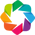

In [35]:
import holoviews as hv
hv.extension('bokeh', inline=False)

In [36]:
df_nb2 = df_nb.select(
    pl.col('neighborhood'),
    pl.col('borough'),
    pl.col('coordinates').list.eval(pl.element().list.get(0)).alias('lng'),
    pl.col('coordinates').list.eval(pl.element().list.get(1)).alias('lat'),
)

hv.Polygons(df_nb2.to_dicts(), kdims=['lng', 'lat'], vdims=['borough']).opts(cmap='tab10', data_aspect=1)

:Polygons   [lng,lat]   (borough)

## 二进制文件

二进制格式方面，Polars 支持 IPC（Arrow IPC）和 Parquet，两者都比 CSV 快得多，因为不需要解析文本、类型信息也直接存在文件里。

1. **IPC** — 进程间传数据的二进制格式，序列化和反序列化都快，大数据可以原样传递。
2. **Parquet** — 列式存储格式，压缩率高，读取时只取需要的列，Spark 等分布式处理也把它当标准。

`DataFrame` 用 `read_*()` / `write_*()`，`LazyFrame` 用 `scan_*()` / `sink_*()`。

- `read_ipc()` / `read_parquet()` — 从文件读成 `DataFrame`
- `write_ipc()` / `write_parquet()` — 把 `DataFrame` 写进文件
- `scan_ipc()` / `scan_parquet()` — 把文件读成 `LazyFrame`
- `sink_ipc()` / `sink_parquet()` — 把 `LazyFrame` 按块写出

`sink_*()` 不把数据一次全放进内存，而是分块处理，所以内存装不下的规模也能对付。下面的代码把多个 CSV 转成一个 IPC 文件。

In [37]:
df_stock = pl.scan_csv('data/stock/**/*.csv', try_parse_dates=True)
df_stock.sink_ipc('data/stock.arrow')

In [38]:
df_stock = pl.read_ipc('data/stock.arrow')
df_stock

symbol,date,open,high,low,close,adj close,volume
str,date,f64,f64,f64,f64,f64,i64
"""ASML""",1999-01-04,11.765625,12.28125,11.765625,12.140625,7.522523,1801867
"""ASML""",1999-01-05,11.859375,14.25,11.71875,13.96875,8.655257,8241600
"""ASML""",1999-01-06,14.25,17.601563,14.203125,16.875,10.456018,16400267
"""ASML""",1999-01-07,14.742188,17.8125,14.53125,16.851563,10.441495,17722133
"""ASML""",1999-01-08,16.078125,16.289063,15.023438,15.796875,9.787995,10696000
…,…,…,…,…,…,…,…
"""TSM""",2023-06-26,102.019997,103.040001,100.089996,100.110001,99.125954,8560000
"""TSM""",2023-06-27,101.150002,102.790001,100.019997,102.080002,101.076591,9732000
"""TSM""",2023-06-28,100.5,101.879997,100.220001,100.919998,99.927986,8160900


上面的函数一个文件对一个数据框，而用 `write_ipc_stream()` / `read_ipc_stream()` 可以把多个数据框依次写进一个文件。

每个数据框是一条独立的记录流，读取时按写入顺序依次取出。下面的代码写出两个数据框。

In [39]:
df1 = pl.DataFrame({"a":[1, 2, 3], "b":["xx", "yyy", "zzzz"]})
df2 = pl.DataFrame({"x":[3.0, 4.0, 6.0, 7.0], "y":[1.0, 2.0, 3.0, 4.0], "z":[0.0, 0.1, 0.2, 0.3]})

with open('data/stream_test.arrow', 'wb') as f:
    df1.write_ipc_stream(f)
    df2.write_ipc_stream(f)

读取时按写出的顺序依次取出。

```{note}
2.0 里连续读取仍需 `use_pyarrow=True`。用默认设置读不到第 2 个之后的数据框——这是目前的实现限制，不是用法问题。
```

In [40]:
with open("data/stream_test.arrow", "rb") as f:
    df1_r = pl.read_ipc_stream(f, use_pyarrow=True)
    df2_r = pl.read_ipc_stream(f, use_pyarrow=True)

print(df1.equals(df1_r), df2.equals(df2_r))

True True
